In [68]:
import itertools
import json
from pathlib import Path
from typing import List, Dict, Optional, Iterable, Tuple

import matplotlib.pyplot as plt
from scipy.stats import linregress
from pydantic import parse_obj_as
import pandas as pd
import numpy as np
from scipy import stats
from IPython.display import display

from utils.statistics.info import ChatInfo, get_model_info, CallInfo, PartyInfo, EmailInfo

In [69]:
pd.set_option('display.float_format', str)
plt.rcParams['figure.figsize'] = (10, 8)

In [70]:
stats_dirpath = Path('/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results')

In [71]:
def get_model_infos(model_type: str):
    for summary_path in stats_dirpath.iterdir():
        with summary_path.open() as f:
            summary_json = json.load(f)
        infos = summary_json['model_type_to_infos'].get(model_type)
        if infos:
            model_info_class = get_model_info(model_type)
            infos = parse_obj_as(List[model_info_class], infos)
            yield str(summary_path), summary_json['report_version'], infos

In [72]:
def get_len(values: Optional[Iterable]):
    return len(values) if values is not None else None

# Chat

In [7]:
chat_infos = list(get_model_infos('Chat'))

In [8]:
def structure_chat_info(chat_infos: Dict[Path, List[ChatInfo]]):
    for summary_path, report_version, infos in chat_infos:
        for chat_info in infos:
            yield {
                'summary_path': summary_path,
                'report_version': report_version,
                'chat_id': chat_info.uid,
                'num_participants': get_len(chat_info.participants),
                'num_messages': get_len(chat_info.messages)
            }

def structure_chat_info_participants(chat_infos: Dict[Path, List[ChatInfo]]):
    for summary_path, report_version, infos in chat_infos:
        for chat_info in infos:
            for party in chat_info.participants:
                yield {
                    'summary_path': summary_path,
                    'report_version': report_version,
                    'chat_id': chat_info.uid,
                    'party_id': party.uid,
                    'role': party.role,
                    'status': party.status,
                    'is_phone_owner': party.is_phone_owner
                }

def structure_chat_info_messages(chat_infos: Dict[Path, List[ChatInfo]]):
    for summary_path, report_version, infos in chat_infos:
        for chat_info in infos:
            for message in chat_info.messages:
                yield {
                    'summary_path': summary_path,
                    'report_version': report_version,
                    'chat_id': chat_info.uid,
                    'message_id': message.uid,
                    'from_role': message.from_.role if message.from_ is not None else None,
                    'from_status': message.from_.status if message.from_ is not None else None,
                    'from_is_phone_owner': message.from_.is_phone_owner if message.from_ is not None else None,
                    'num_tos': get_len(message.to),
                    'len_body_chars': message.len_body_chars,
                    'num_attachments': get_len(message.attachments),
                    'status': message.status,
                    'type': message.type
                }

In [9]:
df_chat_infos = pd.DataFrame(structure_chat_info(chat_infos))
df_chat_participants = pd.DataFrame(structure_chat_info_participants(chat_infos))
df_chat_messages = pd.DataFrame(structure_chat_info_messages(chat_infos))

In [10]:
df_chat_infos

,summary_path,report_version,chat_id,num_participants,num_messages
0,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,650ce6aa-37d5-4cf8-b437-2a99e7b1b1fe,2,1
1,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,67826a0b-89cc-45b1-9591-1cd301d46c07,2,87
2,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,e589f902-e7a3-42bb-9601-831e049b691f,2,20
3,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,14449cd9-982e-4f47-802d-5dbb97d09d6e,2,7
4,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,7ea8e761-a792-421d-830e-8fb2cc2da9ec,2,20
...,...,...,...,...,...
115703,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,86c8e8a3-8680-4dfb-a63b-a6997528b413,3,1
115704,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,65aa4f6e-b258-40bd-9a25-9872b007f123,2,4
115705,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,898e3621-7804-4dfc-829f-c089f17b87a5,2,3
115706,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,ad441a9b-2518-4095-a29a-0434a95cc382,2,6


## [Chat] Total Messages to Total Chat Threads Correlation

In [83]:
chat_total_chats_total_messages = df_chat_messages.groupby('summary_path')\
    .agg(total_messages=('message_id','count'), total_chats=('chat_id','nunique'))\
    .sort_values('total_messages')
with pd.option_context('display.max_rows', len(chat_total_chats_total_messages)):
    display(chat_total_chats_total_messages)

,total_messages,total_chats
summary_path,,
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr98.json,4,4
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr71.json,15,11
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr12.json,63,1
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr16.json,86,18
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr68.json,96,9
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr72.json,134,45
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr22.json,205,66
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr8.json,313,10
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr74.json,504,131


<AxesSubplot:xlabel='total_messages', ylabel='total_chats'>

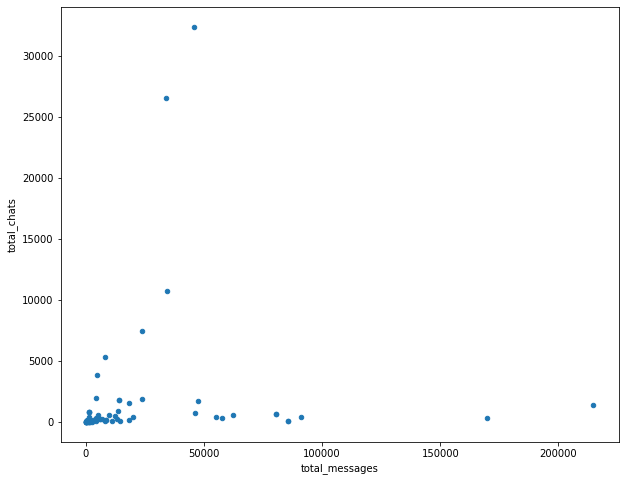

In [84]:
chat_total_chats_total_messages.plot(kind='scatter',x='total_messages',y='total_chats')

In [103]:
chunk_size = 5
num_chunks = np.ceil(len(chat_total_chats_total_messages)/chunk_size)
chunks = np.array_split(chat_total_chats_total_messages, num_chunks)
for i, chunk in enumerate(chunks):
    min_msgs = 1 if i==0 else int(np.mean((chunk.total_messages.min(),chunks[i-1].total_messages.max())))
    max_msgs = np.inf if i==len(chunks)-1 else int(np.mean((chunk.total_messages.max(),chunks[i+1].total_messages.min())))
    mean_chats = chunk.total_chats.mean()
    std_chats = chunk.total_chats.std()
    # print(f'(({min_msgs}, {max_msgs}), ({mean_chats}, {std_chats})),')
    print('Min. Msgs:', min_msgs,
          'Max. Msgs:', max_msgs,
          'Avg: Chats', mean_chats,
          'Std.Dev. Chats:', std_chats)

((1, 115), (8.6, 6.580273550544841)),
((115, 598), (87.8, 70.82866651293105)),
((598, 1178), (127.0, 89.99166628082847)),
((1178, 1387), (589.2, 356.4031425226214)),
((1387, 3469), (70.8, 60.99754093404094)),
((3469, 5522), (1387.4, 1561.832673496108)),
((5522, 8251), (1223.4, 2288.702317908557)),
((8251, 12723), (301.8, 245.19624793214106)),
((12723, 16209), (998.0, 835.2296091494841)),
((16209, 28864), (2309.8, 2992.363898325202)),
((28864, 51148), (14417.4, 14425.840921762585)),
((51148, 83079), (530.8, 138.0170279349617)),
((83079, inf), (470.6, 522.978297828887)),


## [Chat] Independent chat threads

In [22]:
vc_total_chats_per_ufdr = df_chat_infos.groupby('summary_path').chat_id.nunique().sort_values()
vc_total_chats_per_ufdr

summary_path
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr12.json        1
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr98.json        4
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr68.json        9
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr8.json        10
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr71.json       12
                                                                   ...  
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr54.json     5316
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr66.json     7504
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr62.json    10751
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr63.json    26520
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr65.json    32414
Name: chat_id, Length: 65, dtype: int64

In [28]:
sigma, loc, scale = stats.lognorm.fit(vc_total_chats_per_ufdr)
mu = np.log(scale)
mu, sigma

(5.628179374765531, 1.9658015416633932)

## [Chat] Total participants per chat thread

In [117]:
total_participants_per_chat = df_chat_participants.groupby('chat_id').party_id.nunique()
total_participants_per_chat

chat_id
0000312e-034b-4c30-85dd-a86e0c580e17    2
0001207b-845e-4940-8b46-6b33b807527a    2
000162d5-31a9-4dc5-ae51-8e0e7472b1a2    2
00028cd7-c96f-4a45-b843-6714505d03a7    1
00035b7e-cb84-44ba-99ce-617e0dbe3d3c    1
                                       ..
fffc6f66-93b2-49f1-a810-ea02a8bf85ff    1
fffd3493-86f0-4eec-b4c0-6c02433d58fe    2
fffe8f41-d75b-4991-a29f-b8547c9e81d2    1
ffff8b82-c393-46fc-8188-912f89ab0151    1
ffffcc89-0050-492f-b8e3-bc9873cdba54    1
Name: party_id, Length: 100218, dtype: int64

In [118]:
total_participants_per_chat.describe()

count             100218.0
mean    2.2524097467520803
std      48.23586853754177
min                    1.0
25%                    1.0
50%                    1.0
75%                    2.0
max                 6166.0
Name: party_id, dtype: float64

In [120]:
total_participants_per_chat.plot(kind='box')

<AxesSubplot:>

In [177]:
sigma, loc, scale = stats.lognorm.fit(total_participants_per_chat)
mu = np.log(scale)
mu, sigma

(-3.944948273504255, 6.798648375832828)

## [Chat] Total messages per chat thread

In [189]:
total_messages_per_chat = df_chat_messages.groupby('chat_id').message_id.nunique()
total_messages_per_chat

chat_id
0000312e-034b-4c30-85dd-a86e0c580e17    23
0001207b-845e-4940-8b46-6b33b807527a     1
000162d5-31a9-4dc5-ae51-8e0e7472b1a2     1
00028cd7-c96f-4a45-b843-6714505d03a7    41
00035b7e-cb84-44ba-99ce-617e0dbe3d3c     1
                                        ..
fffd3493-86f0-4eec-b4c0-6c02433d58fe     2
fffe8f41-d75b-4991-a29f-b8547c9e81d2     1
fffea9db-ddf9-4992-8d67-9d1a0ec50c84     1
ffff8b82-c393-46fc-8188-912f89ab0151     1
ffffcc89-0050-492f-b8e3-bc9873cdba54     1
Name: message_id, Length: 108182, dtype: int64

In [190]:
total_messages_per_chat.describe()

count             108182.0
mean    12.044499084875488
std      326.4435841157721
min                    1.0
25%                    1.0
50%                    1.0
75%                    1.0
max                64725.0
Name: message_id, dtype: float64

In [1]:
total_messages_per_chat.plot(kind='box')

NameError: name 'total_messages_per_chat' is not defined

In [196]:
sigma, loc, scale = stats.lognorm.fit(total_messages_per_chat)
mu = np.log(scale)
mu, sigma

(-7.748185565757008, 5.552943664725657)

In [198]:
test=pd.Series(np.random.lognormal(mu, sigma, size=1000000)).astype(int)
test[test<1]=1

<AxesSubplot:>

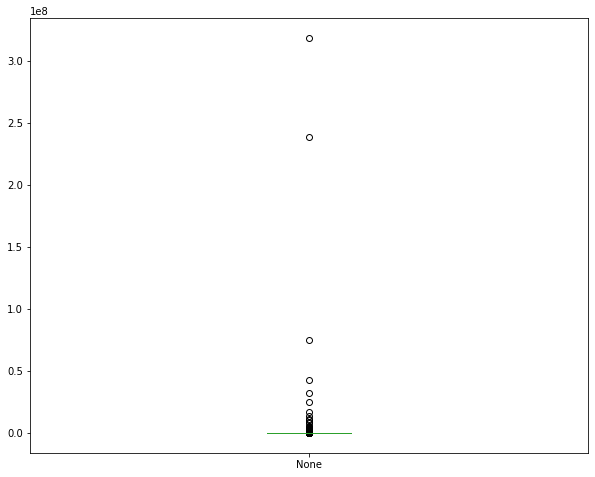

In [204]:
test.plot(kind='box')

In [199]:
test.describe()

count            1000000.0
mean             989.31226
std     410956.24784898525
min                    1.0
25%                    1.0
50%                    1.0
75%                    1.0
max            318637062.0
dtype: float64

Probability that chat is empty (0 messages)

In [206]:
1 - df_chat_messages.chat_id.nunique() / df_chat_infos.chat_id.nunique()

0.02693027272073112

## [Chat] Reply messages index delta

In [70]:
test=pd.Series(np.random.lognormal(1.5, 0.5, size=1000000)).astype(int)
test[test<1]=1
test.describe()

count           1000000.0
mean             4.584019
std     2.722912084862312
min                   1.0
25%                   3.0
50%                   4.0
75%                   6.0
max                  58.0
dtype: float64

<AxesSubplot:>

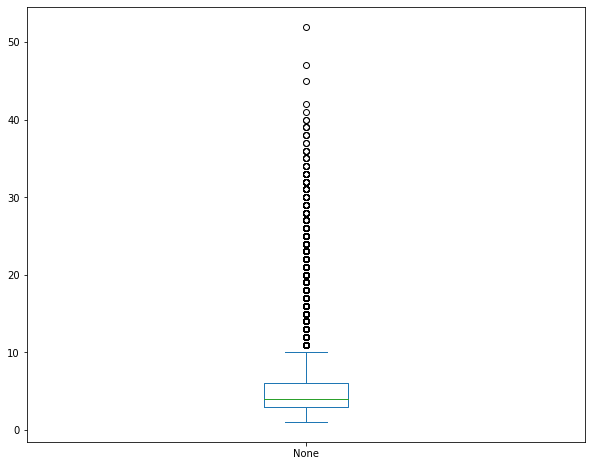

In [69]:
test.plot(kind='box')

In [19]:
df_chat_infos[df_chat_infos.chat_id=='2159354b-6be4-41b9-b6c8-5513c285a96f']

,summary_path,report_version,chat_id,num_participants,num_messages
106686,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2159354b-6be4-41b9-b6c8-5513c285a96f,8,44


In [20]:
df_chat_participants[df_chat_participants.chat_id=='2159354b-6be4-41b9-b6c8-5513c285a96f']

,summary_path,report_version,chat_id,party_id,role,status,is_phone_owner
217023,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2159354b-6be4-41b9-b6c8-5513c285a96f,496552af-87f8-4c81-9ac0-4db45b25d9ff,None,None,False
217024,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2159354b-6be4-41b9-b6c8-5513c285a96f,5224ea5d-1ff2-466b-9f79-0afbe06a37d6,None,None,True
217025,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2159354b-6be4-41b9-b6c8-5513c285a96f,2d3deea6-27fe-4816-86e9-a0219c41e605,None,None,False
217026,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2159354b-6be4-41b9-b6c8-5513c285a96f,8ed7ce7c-be7b-4c18-af0a-6991d616ffa0,None,None,False
217027,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2159354b-6be4-41b9-b6c8-5513c285a96f,e0834539-f0f1-44c3-938f-bfcf51cd6006,None,None,False
217028,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2159354b-6be4-41b9-b6c8-5513c285a96f,b4e8378a-e710-4362-b074-32ddf8361a9d,None,None,False
217029,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2159354b-6be4-41b9-b6c8-5513c285a96f,42b43a07-a917-4921-b78e-ee6c732ebe73,None,None,False
217030,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2159354b-6be4-41b9-b6c8-5513c285a96f,bd56eb93-cdc8-4d75-9ec8-6193b21da891,None,None,False


In [18]:
df_chat_messages[(df_chat_messages.report_version=='7.48')& (df_chat_messages.num_tos>2)]

,summary_path,report_version,chat_id,message_id,from_role,from_status,from_is_phone_owner,num_tos,len_body_chars,num_attachments,status,type
1246833,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2159354b-6be4-41b9-b6c8-5513c285a96f,4c867fe0-1432-4831-8c45-17541683d88c,From,None,True,3.0,19.0,0,Delivered,AppMessage
1386589,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,8a3a78e4-a093-4a3c-ad9a-1541bb30acef,ecf3537e-a17e-40ad-9745-aaf45b80b5ac,From,None,True,4.0,16.0,0,Sent,AppMessage
1386591,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,8a3a78e4-a093-4a3c-ad9a-1541bb30acef,4c0fa167-0865-4e32-a2b5-d0feaff346f3,From,None,True,4.0,6.0,0,Sent,AppMessage
1392344,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2c0eb419-b3b0-44e5-b06e-f0ec32c9c9fb,61de603b-de60-4849-8974-82591081cb3e,From,None,True,3.0,67.0,0,Sent,Sms
1392348,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,2c0eb419-b3b0-44e5-b06e-f0ec32c9c9fb,4a4cc604-a7e8-46d9-bd13-9d0b73e89d1f,From,None,True,3.0,7.0,0,Sent,Sms
1392397,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,ada05392-cded-4897-b726-3187b4c1e838,522901f5-8138-475d-8a02-4531f3dce46e,From,None,True,4.0,36.0,0,Sent,Sms
1392398,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.48,ada05392-cded-4897-b726-3187b4c1e838,fcecee1d-f89c-4597-bfb4-ece1bdd3fe61,From,None,True,4.0,39.0,0,Sent,Sms


In [48]:
df_chat_messages.num_tos.describe()

count    1.493925e+06
mean     3.172194e-01
std      1.080453e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+00
max      2.470000e+02
Name: num_tos, dtype: float64

In [156]:
df_chat_messages['from.is_phone_owner'].value_counts(dropna=False)

NaN      1273733
True      195861
False      24331
Name: from.is_phone_owner, dtype: int64

# Call

In [73]:
call_infos = list(get_model_infos('Call'))

In [74]:
def structure_call_info(call_infos: List[Tuple[Path, str, List[CallInfo]]]):
    for summary_path, report_version, infos in call_infos:
        for call_info in infos:
            yield {
                'summary_path': summary_path,
                'report_version': report_version,
                'call_id': call_info.uid,
                'deleted': call_info.deleted,
                'direction': call_info.direction,
                'type': call_info.type,
                'duration': call_info.duration,
                'num_parties': get_len(call_info.parties)
            }

def structure_call_info_participants(call_infos: List[Tuple[Path, str, List[CallInfo]]]):
    for summary_path, report_version, infos in call_infos:
        for call_info in infos:
            if call_info.parties is not None:
                for party in call_info.parties:
                    yield {
                        'summary_path': summary_path,
                        'report_version': report_version,
                        'call_id': call_info.uid,
                        'party_id': party.uid,
                        'is_phone_owner': party.is_phone_owner,
                        'identifier': party.identifier
                    }

In [76]:
df_call_infos = pd.DataFrame(structure_call_info(call_infos))
df_call_info_participants = pd.DataFrame(structure_call_info_participants(call_infos))

In [77]:
df_call_infos

,summary_path,report_version,call_id,deleted,direction,type,duration,num_parties
0,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,7bec04fa-fab5-4b0b-a15e-92aba90f52f2,Intact,Incoming,Incoming,76.0,1.0
1,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,5e0f3028-29e2-4330-a1de-62cc291b98fd,Intact,Incoming,Incoming,60.0,1.0
2,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,787fa8a6-a2d4-42f0-bc4d-ef6d8061cf61,Intact,Incoming,Incoming,204.0,1.0
3,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,1ce32bcf-aa31-4b07-9e9a-e13d9d8c07d4,Intact,Incoming,Incoming,152.0,1.0
4,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,70e789ba-fb01-44f5-9371-eb7908eef4d9,Intact,Incoming,Incoming,23.0,1.0
...,...,...,...,...,...,...,...,...
50929,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,e22aff7d-b2db-4f74-9c2f-98cf215d3c9f,Intact,None,Outgoing,0.0,2.0
50930,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,47bb8806-1245-4342-97b3-b6b35b786934,Intact,None,Missed,0.0,2.0
50931,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,1ad7ce0c-69df-4242-b3a9-bd3158e8bb3c,Intact,None,Outgoing,0.0,2.0
50932,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,eed0041e-918e-4f37-ad38-40ae11485449,Intact,None,Missed,0.0,2.0


In [78]:
df_call_info_participants

,summary_path,report_version,call_id,party_id,is_phone_owner,identifier
0,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,7bec04fa-fab5-4b0b-a15e-92aba90f52f2,d7c4662f-0607-4194-b5c4-4572ee6929bb,None,0.0
1,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,5e0f3028-29e2-4330-a1de-62cc291b98fd,9489900b-82f7-4ebf-92b6-8426247db917,None,0.0
2,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,787fa8a6-a2d4-42f0-bc4d-ef6d8061cf61,9c888de3-96e7-434c-8220-109571e8da5c,None,1.0
3,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,1ce32bcf-aa31-4b07-9e9a-e13d9d8c07d4,50a199e5-90d2-424c-8a47-d7fb077d405e,None,2.0
4,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,70e789ba-fb01-44f5-9371-eb7908eef4d9,32607356-9321-4556-b0bf-c99e8a3ea55e,None,3.0
...,...,...,...,...,...,...
54700,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,1ad7ce0c-69df-4242-b3a9-bd3158e8bb3c,2194dc9a-62af-401f-a17f-a05e60ac5e43,None,342.0
54701,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,eed0041e-918e-4f37-ad38-40ae11485449,2716c14d-8f34-4b39-9067-e3ad352f8c76,None,343.0
54702,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,eed0041e-918e-4f37-ad38-40ae11485449,c6c100c3-ec35-4180-a50b-00202016669d,True,338.0
54703,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,933fb180-d976-4c52-b15f-15de60e97b69,115b5b0b-730a-4209-a930-9a176a139534,None,344.0


## [Call] Direction

There is no Direction info prior to version 5.6.1.
There are no missing values for this field.

In [15]:
df_call_infos.groupby('report_version').direction.value_counts(dropna=False, normalize=True).sort_index(ascending=False)

report_version  direction
7.48            Outgoing     0.4647887323943662
                Incoming     0.5352112676056338
7.34            Unknown     9.7551458394303e-05
                Outgoing     0.4801482782167593
                Incoming     0.5197541703248464
5.6.1           Outgoing    0.42016806722689076
                Incoming     0.5798319327731093
5.6             NaN                         1.0
5.3.2.1         NaN                         1.0
5.3.1.0         NaN                         1.0
5.2.0.0         NaN                         1.0
5.0.0.0         NaN                         1.0
4.2.0.1         NaN                         1.0
3.1.0.0         NaN                         1.0
3.0             NaN                         1.0
Name: direction, dtype: float64

Group by UFDR and average the ratios of the values

In [16]:
# Since there are no observed missing values for this field, we can drop NaN and tally everything...
df_call_infos.groupby('summary_path').direction.value_counts(normalize=True).groupby('direction').mean()

direction
Incoming      0.503993617882208
Outgoing     0.4959329930087358
Unknown    0.001321003963011889
Name: direction, dtype: float64

## [Call] Type

Some data in the dataset is missing obviously common values (e.g., v7.48 has only Outgoing)

In [17]:
df_call_infos.groupby('report_version').type.value_counts(dropna=False, normalize=True).sort_index(ascending=False)

report_version  type     
7.48            Outgoing      0.004694835680751174
                NaN             0.9953051643192489
7.34            Unknown        9.7551458394303e-05
                Rejected      0.003219198127011999
                Outgoing        0.3005560433128475
                Missed          0.1009657594381036
                Incoming       0.21402789971710076
                Cancelled     0.000390205833577212
                NaN            0.38074334211296457
5.6.1           Outgoing       0.39327731092436974
                Missed          0.1865546218487395
                Incoming       0.25882352941176473
                NaN            0.16134453781512606
5.6             Outgoing       0.42475728155339804
                Missed         0.19902912621359223
                Incoming        0.3762135922330097
5.3.2.1         Unknown        0.00889942074776198
                Rejected    0.00021063717746182202
                Outgoing        0.5287519747235387
     

The idea is that once we generate a Direction value, we can generate a Type value (because when Direction=Outgoing, Type cannot be Incoming for example).
We can observe some data (e.g. version 7.48) is bad because it only has Type values either Outgoing or NaN.

In [18]:
df_call_infos.groupby(['direction','report_version']).type.value_counts(dropna=False, normalize=True)

direction  report_version  type     
Incoming   5.6.1           Incoming       0.4463768115942029
                           Missed         0.3217391304347826
                           NaN            0.2318840579710145
           7.34            Incoming      0.41178678678678676
                           NaN            0.3894519519519519
                           Missed        0.19425675675675674
                           Rejected    0.0045045045045045045
           7.48            NaN                           1.0
Outgoing   5.6.1           Outgoing                    0.936
                           NaN                         0.064
           7.34            Outgoing       0.6259650548557497
                           NaN           0.37139374238114586
                           Rejected    0.0018285249898415277
                           Cancelled   0.0008126777732629012
           7.48            NaN              0.98989898989899
                           Outgoing     0.010101

We assume UFDRs with 2 or less values of Type are probably unrepresentative data, and should be filtered out.

In [19]:
s_call_ufdrs_with_gt2_type = df_call_infos.groupby('summary_path').type.nunique() > 2
s_call_ufdrs_with_gt2_type = s_call_ufdrs_with_gt2_type[s_call_ufdrs_with_gt2_type].index
s_call_ufdrs_with_gt2_type

Index([  /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr0.json,
         /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr1.json,
       /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr100.json,
       /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr103.json,
       /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr107.json,
        /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr13.json,
        /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr16.json,
        /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr18.json,
        /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr20.json,
        /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr23.json,
        /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr34.json,
        /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr36.json,
        /mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr37.json,
        /mnt/CTO/Users/Da

Filter only UFDRs with enough Type content (as explained above), group by Direction, and compute mean Type value likelihood by Direction

In [21]:
df_call_ufdrs_with_gt2_type = df_call_infos[df_call_infos.summary_path.isin(s_call_ufdrs_with_gt2_type)]
df_call_ufdrs_with_gt2_type\
    .groupby('direction').type.value_counts(dropna=False, normalize=True)

direction  type     
Incoming   Incoming      0.5278776978417267
           Missed       0.25764388489208634
           NaN          0.20908273381294964
           Rejected     0.00539568345323741
Outgoing   Outgoing      0.8177109028120375
           NaN          0.17908238776517021
           Rejected    0.002220029600394672
           Cancelled   0.000986679822397632
Unknown    Unknown                      1.0
Name: type, dtype: float64

## [Call] Duration

Durations are missing in some cases

In [36]:
df_call_infos[df_call_infos.duration.isna()].value_counts(['report_version','direction','type'], dropna=False).sort_index(ascending=False)

report_version  direction  type    
7.48            Outgoing   NaN          28
                Incoming   NaN          32
7.34            Unknown    Unknown       1
                Outgoing   NaN          98
                           Outgoing    868
                Incoming   NaN         154
                           Rejected     24
                           Missed      678
                           Incoming    126
5.6.1           Outgoing   NaN          11
                Incoming   NaN          65
5.3.2.1         NaN        Unknown      16
                           Outgoing    284
                           Missed      662
                           Incoming      4
5.3.1.0         NaN        Outgoing      1
5.2.0.0         NaN        Unknown      21
                           Outgoing     42
                           Missed      136
                           Incoming    122
dtype: int64

We can be assured all calls with non-zero duration  do not have Direction/Type values other than Incoming & Outgoing

In [35]:
df_call_infos[df_call_infos.duration>0].value_counts(['report_version','direction','type'], dropna=False).sort_index(ascending=False)

report_version  direction  type    
7.48            Outgoing   NaN           34
                           Outgoing       1
                Incoming   NaN           51
7.34            Outgoing   NaN         1164
                           Outgoing    1865
                Incoming   NaN         1022
                           Incoming    2068
5.6.1           Outgoing   NaN            5
                           Outgoing     154
                Incoming   NaN           15
                           Incoming     151
5.6             NaN        Outgoing     111
                           Incoming     155
5.3.2.1         NaN        Unknown      153
                           Outgoing    8043
                           Incoming    5449
5.3.1.0         NaN        NaN            8
                           Outgoing    2792
                           Incoming    2005
5.2.0.0         NaN        Unknown       32
                           Outgoing    2221
                           Incoming    1

There is no clear correlation between zero duration and Direction/Type values

In [34]:
df_call_infos[df_call_infos.duration==0].value_counts(['report_version','direction','type'], dropna=False).sort_index(ascending=False)

report_version  direction  type     
7.48            Outgoing   NaN            36
                Incoming   NaN            31
7.34            Outgoing   NaN           566
                           Rejected        9
                           Outgoing      348
                           Cancelled       4
                Incoming   NaN           899
                           Missed        357
5.6.1           Outgoing   Outgoing       80
                Incoming   Missed        111
                           Incoming        3
5.6             NaN        Outgoing       64
                           Missed         82
5.3.2.1         NaN        Rejected        4
                           Outgoing     1714
                           Missed       2618
                           Incoming       43
5.3.1.0         NaN        Outgoing     1199
                           Missed       2040
                           Incoming      198
5.2.0.0         NaN        Unknown        48
                  

Distribution of durations by Direction/Type
Besides Incoming/Outgoing, we can ignore all Type values because they are insignificant or outdated (e.g., Unknown doesn't appear in report versions >= 7)
Incoming & Outgoing will naturally have probability functions to sample from. If Type==Missed, then Duration=0

In [48]:
df_call_infos.fillna({'type':df_call_infos.direction}).groupby('type').duration.describe()

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Cancelled,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Incoming,15742.0,291.5477702960234,1206.478467939323,0.0,26.0,78.0,261.0,41772.0
Missed,7279.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Outgoing,24144.0,158.15312292909212,736.6351578019592,0.0,2.0,28.0,107.0,63249.0
Rejected,83.0,0.012048192771084338,0.10976425998969035,0.0,0.0,0.0,0.0,1.0
Unknown,293.0,377.99658703071674,3863.9199500151785,0.0,0.0,51.0,66.0,63233.0
incoming,1.0,3379.0,NaN,3379.0,3379.0,3379.0,3379.0,3379.0
outgoing,7.0,10.714285714285714,1.8898223650461357,10.0,10.0,10.0,10.0,15.0


We should also factor in missing Duration fields in probability calculation

In [58]:
df_call_infos.fillna({'type':df_call_infos.direction}).groupby('type').apply(lambda g: g.duration.isna().sum()).sort_values(ascending=False)

type
Missed       1476
Outgoing     1332
Incoming      503
Unknown        38
Rejected       24
Cancelled       0
incoming        0
outgoing        0
dtype: int64

In [59]:
df_call_infos.fillna({'type':df_call_infos.direction}).groupby(['report_version', 'type']).apply(lambda g: g.duration.isna().sum()).sort_values(ascending=False)

report_version  type     
7.34            Outgoing     966
                Missed       678
5.3.2.1         Missed       662
                Outgoing     284
7.34            Incoming     280
5.2.0.0         Missed       136
                Incoming     122
5.6.1           Incoming      65
5.2.0.0         Outgoing      42
7.48            Incoming      32
                Outgoing      28
7.34            Rejected      24
5.2.0.0         Unknown       21
5.3.2.1         Unknown       16
5.6.1           Outgoing      11
5.3.2.1         Incoming       4
5.3.1.0         Outgoing       1
7.34            Unknown        1
5.6             Incoming       0
                Missed         0
5.3.2.1         Rejected       0
5.6.1           Missed         0
7.34            Cancelled      0
5.6             Outgoing       0
3.0             Incoming       0
5.3.1.0         Missed         0
3.0             Missed         0
                Outgoing       0
                Unknown        0
3.1.0.0         I

Relationship between missing Type and duration

In [67]:
df_call_infos.fillna({'type':'MISSING'}).groupby('type').duration.describe()

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Cancelled,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Incoming,13724.0,310.311133780239,1229.4590928995435,0.0,33.0,93.0,291.0,41772.0
MISSING,3831.0,159.83241973375098,869.1526296229796,0.0,0.0,11.0,60.0,27031.0
Missed,7279.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Outgoing,22339.0,158.34433054299654,743.2249048993632,0.0,2.0,29.0,110.0,63249.0
Rejected,83.0,0.012048192771084338,0.10976425998969035,0.0,0.0,0.0,0.0,1.0
Unknown,293.0,377.99658703071674,3863.9199500151785,0.0,0.0,51.0,66.0,63233.0
incoming,1.0,3379.0,NaN,3379.0,3379.0,3379.0,3379.0,3379.0
outgoing,7.0,10.714285714285714,1.8898223650461357,10.0,10.0,10.0,10.0,15.0


In [64]:
df_call_infos.fillna({'type':'MISSING'}).groupby('type').apply(lambda g: g.duration.isna().sum())

type
Cancelled       0
Incoming      252
MISSING       388
Missed       1476
Outgoing     1195
Rejected       24
Unknown        38
incoming        0
outgoing        0
dtype: int64

In [66]:
df_call_infos.fillna({'type':'MISSING'}).groupby(['report_version','type']).apply(lambda g: g.duration.isna().sum()).sort_values(ascending=False)

report_version  type     
7.34            Outgoing     868
                Missed       678
5.3.2.1         Missed       662
                Outgoing     284
7.34            MISSING      252
5.2.0.0         Missed       136
7.34            Incoming     126
5.2.0.0         Incoming     122
5.6.1           MISSING       76
7.48            MISSING       60
5.2.0.0         Outgoing      42
7.34            Rejected      24
5.2.0.0         Unknown       21
5.3.2.1         Unknown       16
                Incoming       4
7.34            Unknown        1
5.3.1.0         Outgoing       1
5.3.2.1         Rejected       0
5.6             Incoming       0
3.0             Incoming       0
5.6             Missed         0
                Outgoing       0
5.6.1           Missed         0
                Outgoing       0
7.34            Cancelled      0
5.6.1           Incoming       0
5.3.1.0         Missed         0
3.0             Missed         0
4.2.0.1         Incoming       0
3.0             O

Analysis of zeros (which will be treated as category in implementation)

In [136]:
df_call_infos[df_call_infos.duration.isna()].fillna({'type':'MISSING'}).type.value_counts() / df_call_infos.fillna({'type':'MISSING'}).groupby('type').size()

Cancelled                    NaN
Incoming    0.018030910131654265
MISSING      0.09196492059729794
Missed       0.16858937749857225
Outgoing    0.050777598368318175
Rejected     0.22429906542056074
Unknown       0.1148036253776435
incoming                     NaN
outgoing                     NaN
dtype: float64

In [137]:
df_call_infos[df_call_infos.duration==0].fillna({'type':'MISSING'}).type.value_counts() / df_call_infos.fillna({'type':'MISSING'}).groupby('type').size()

Cancelled                   1.0
Incoming    0.02160847166571265
MISSING      0.3631192225645888
Missed       0.8314106225014277
Outgoing     0.1967366363559106
Rejected     0.7663551401869159
Unknown     0.27492447129909364
incoming                    NaN
outgoing                    NaN
dtype: float64

In [138]:
df_call_infos[df_call_infos.duration>0].fillna({'type':'MISSING'}).type.value_counts() / df_call_infos.fillna({'type':'MISSING'}).groupby('type').size()

Cancelled                    NaN
Incoming      0.9603606182026331
MISSING       0.5449158568381133
Missed                       NaN
Outgoing      0.7524857652757713
Rejected    0.009345794392523364
Unknown       0.6102719033232629
incoming                     1.0
outgoing                     1.0
dtype: float64

Perform both Type values in {Incoming, Outgoing, Nan (MISSING)}

In [147]:
# Incoming
sigma, loc, scale = stats.lognorm.fit(df_call_infos[df_call_infos.type=='Incoming'].duration.dropna())
mu = np.log(scale)
print('Incoming', mu, sigma)
# Outgoing
sigma, loc, scale = stats.lognorm.fit(df_call_infos[df_call_infos.type=='Outgoing'].duration.dropna())
mu = np.log(scale)
print('Outgoing', mu, sigma)
# NaN (MISSING)
sigma, loc, scale = stats.lognorm.fit(df_call_infos[df_call_infos.type.isna()].duration.dropna())
mu = np.log(scale)
print('MISSING', mu, sigma)

Incoming 4.59064990938373 1.5003724288432214
Outgoing 1.2914590804697423 7.502523965389088
MISSING 4.292711544294177 12.618380449778662


# Entities

## Entities: Email

In [9]:
email_infos = list(get_model_infos('Email'))

In [10]:
def structure_email_participants(email_infos: Dict[Path, List[EmailInfo]]):
    for summary_path, report_version, infos in email_infos:
        for email_info in infos:
            for party in itertools.chain([email_info.from_] ,email_info.to, email_info.cc, email_info.bcc):
                if party:
                    yield {
                        'summary_path': summary_path,
                        'report_version': report_version,
                        'email_id': email_info.uid,
                        'party_id': party.uid,
                        'role': party.role,
                        'status': party.status,
                        'is_phone_owner': party.is_phone_owner
                    }

In [11]:
df_email_info_participants = pd.DataFrame(structure_email_participants(email_infos))

### [Email] Total Emails to Total Parties Correlation

In [12]:
df_email_info_participants.is_phone_owner.value_counts(dropna=False)

None     216477
True       2004
False      1968
Name: is_phone_owner, dtype: int64

In [13]:
# ignore parties who are the device owner
df_num_email_parties = df_email_info_participants[df_email_info_participants.is_phone_owner!=True]\
    .groupby('summary_path').agg(total_emails=('email_id','nunique'), total_parties=('party_id','nunique'))\
    .sort_values('total_emails')
df_num_email_parties

,total_emails,total_parties
summary_path,,
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr87.json,1,2
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr86.json,1,2
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr72.json,5,9
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr19.json,6,12
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr16.json,7,14
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr61.json,11,22
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr98.json,12,23
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr97.json,21,32
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr24.json,26,28


In [101]:
fig, ax = plt.subplots(figsize=(15,10))
df_num_email_parties.plot(kind='scatter', x='total_emails', y='total_parties', ax=ax)

# Use least squares instead of np.polyfit so that the line intercept is 0
mean_slope,_,_,_ = np.linalg.lstsq(df_num_email_parties.total_emails.values[:,np.newaxis], df_num_email_parties.total_parties)
ax.plot(df_num_email_parties.total_emails, mean_slope*df_num_email_parties.total_emails)

window=2
rstd = df_num_email_parties.total_parties.rolling(window=window).std().bfill()

std_slope,_,_,_ = np.linalg.lstsq(df_num_email_parties.total_emails.values[:,np.newaxis], rstd)
ax.plot(df_num_email_parties.total_emails, std_slope*df_num_email_parties.total_emails)

# rmean = df_num_email_parties.total_parties.rolling(window=window).mean()
# ax.plot(df_num_email_parties.total_emails,rmean, 'orange')
# ax.plot(df_num_email_parties.total_emails,df_num_email_parties.total_parties+rstd, 'purple')
# ax.plot(df_num_email_parties.total_emails,df_num_email_parties.total_parties-rstd, 'cyan')

/tmp/ipykernel_390928/3838148320.py:5: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  mean_slope,_,_,_ = np.linalg.lstsq(df_num_email_parties.total_emails.values[:,np.newaxis], df_num_email_parties.total_parties)
/tmp/ipykernel_390928/3838148320.py:11: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  std_slope,_,_,_ = np.linalg.lstsq(df_num_email_parties.total_emails.values[:,np.newaxis], rstd)


In [102]:
mean_slope, std_slope

(array([2.56856311]), array([1.45455591]))

## Entities: Calls

In [80]:
df_call_info_participants

,summary_path,report_version,call_id,party_id,is_phone_owner,identifier
0,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,7bec04fa-fab5-4b0b-a15e-92aba90f52f2,d7c4662f-0607-4194-b5c4-4572ee6929bb,None,0.0
1,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,5e0f3028-29e2-4330-a1de-62cc291b98fd,9489900b-82f7-4ebf-92b6-8426247db917,None,0.0
2,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,787fa8a6-a2d4-42f0-bc4d-ef6d8061cf61,9c888de3-96e7-434c-8220-109571e8da5c,None,1.0
3,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,1ce32bcf-aa31-4b07-9e9a-e13d9d8c07d4,50a199e5-90d2-424c-8a47-d7fb077d405e,None,2.0
4,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,7.34,70e789ba-fb01-44f5-9371-eb7908eef4d9,32607356-9321-4556-b0bf-c99e8a3ea55e,None,3.0
...,...,...,...,...,...,...
54700,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,1ad7ce0c-69df-4242-b3a9-bd3158e8bb3c,2194dc9a-62af-401f-a17f-a05e60ac5e43,None,342.0
54701,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,eed0041e-918e-4f37-ad38-40ae11485449,2716c14d-8f34-4b39-9067-e3ad352f8c76,None,343.0
54702,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,eed0041e-918e-4f37-ad38-40ae11485449,c6c100c3-ec35-4180-a50b-00202016669d,True,338.0
54703,/mnt/CTO/Users/DanielHurwitz/Titan/statistics/re...,5.3.2.1,933fb180-d976-4c52-b15f-15de60e97b69,115b5b0b-730a-4209-a930-9a176a139534,None,344.0


In [81]:
df_call_info_participants.is_phone_owner.value_counts(dropna=False)

None     47461
False     4890
True      2354
Name: is_phone_owner, dtype: int64

In [83]:
# ignore parties who are the device owner
df_num_call_identifiers = df_call_info_participants[df_call_info_participants.is_phone_owner!=True]\
    .groupby('summary_path').agg(total_calls=('call_id','nunique'), total_identifiers=('identifier','nunique'))\
    .sort_values('total_calls')
df_num_call_identifiers

,total_calls,total_identifiers
summary_path,,
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr39.json,2,1
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr24.json,2,1
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr19.json,2,0
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr67.json,19,12
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr68.json,20,11
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr105.json,22,1
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr54.json,27,1
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr8.json,43,6
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results/ufdr98.json,69,22


In [87]:
fig, ax = plt.subplots(figsize=(15,10))
df_num_call_identifiers.plot(kind='scatter', x='total_calls', y='total_identifiers', ax=ax)

# Use least squares instead of np.polyfit so that the line intercept is 0
mean_slope,_,_,_ = np.linalg.lstsq(df_num_call_identifiers.total_calls.values[:,np.newaxis], df_num_call_identifiers.total_identifiers)
ax.plot(df_num_call_identifiers.total_calls, mean_slope*df_num_call_identifiers.total_calls)

window=2
rstd = df_num_call_identifiers.total_identifiers.rolling(window=window).std().bfill()

std_slope,_,_,_ = np.linalg.lstsq(df_num_call_identifiers.total_calls.values[:,np.newaxis], rstd)
ax.plot(df_num_call_identifiers.total_calls, std_slope*df_num_call_identifiers.total_calls)

/tmp/ipykernel_579601/2544998145.py:5: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  mean_slope,_,_,_ = np.linalg.lstsq(df_num_call_identifiers.total_calls.values[:,np.newaxis], df_num_call_identifiers.total_identifiers)
/tmp/ipykernel_579601/2544998145.py:11: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  std_slope,_,_,_ = np.linalg.lstsq(df_num_call_identifiers.total_calls.values[:,np.newaxis], rstd)


In [88]:
mean_slope, std_slope

(array([0.14260198]), array([0.04221766]))

## Entities: Chats

We need to correlate total number of chat messages (not chat threads) to number of parties

In [13]:
df_chat_participants.is_phone_owner.value_counts(dropna=False)

None     137320
True      86311
False      8525
Name: is_phone_owner, dtype: int64

In [65]:
df_num_chat_parties = df_chat_participants[df_chat_participants.is_phone_owner!=True]\
    .groupby('summary_path',).party_id.nunique().to_frame('total_parties')\
    .merge(df_chat_messages.groupby('summary_path').message_id.nunique(), on='summary_path')\
    .rename(columns={'message_id': 'total_messages'})\
    .sort_values('total_messages')
df_num_chat_parties

,total_parties,total_messages
summary_path,,
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results_2022-03-06/ufdr98.json,2,4
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results_2022-03-06/ufdr71.json,11,15
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results_2022-03-06/ufdr12.json,1,63
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results_2022-03-06/ufdr68.json,10,96
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results_2022-03-06/ufdr72.json,232,134
...,...,...
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results_2022-03-06/ufdr39.json,111,85588
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results_2022-03-06/ufdr24.json,111,85588
/mnt/CTO/Users/DanielHurwitz/Titan/statistics/results_2022-03-06/ufdr40.json,440,91192


/tmp/ipykernel_579601/3709568061.py:5: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  mean_slope,_,_,_ = np.linalg.lstsq(df_num_chat_parties.total_messages.values[:,np.newaxis], df_num_chat_parties.total_parties)
/tmp/ipykernel_579601/3709568061.py:11: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  std_slope,_,_,_ = np.linalg.lstsq(df_num_chat_parties.total_messages.values[:,np.newaxis], rstd)


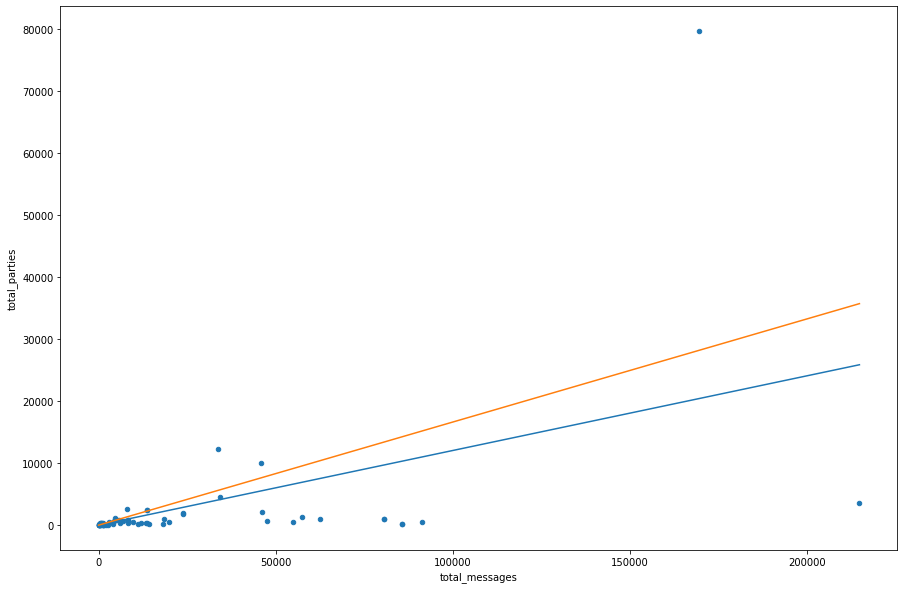

In [67]:
fig, ax = plt.subplots(figsize=(15,10))
df_num_chat_parties.plot(kind='scatter', x='total_messages', y='total_parties', ax=ax)

# Use least squares instead of np.polyfit so that the line intercept is 0
mean_slope,_,_,_ = np.linalg.lstsq(df_num_chat_parties.total_messages.values[:,np.newaxis], df_num_chat_parties.total_parties)
ax.plot(df_num_chat_parties.total_messages, mean_slope*df_num_chat_parties.total_messages)

window=2
rstd = df_num_chat_parties.total_parties.rolling(window=window).std().bfill()

std_slope,_,_,_ = np.linalg.lstsq(df_num_chat_parties.total_messages.values[:,np.newaxis], rstd)
ax.plot(df_num_chat_parties.total_messages, std_slope*df_num_chat_parties.total_messages)

In [35]:
mean_slope, std_slope

(array([1.80172926]), array([1.55424099]))